# Data Check: Lead-Lag Features

Quick visual check for EWLL lead-lag pipeline data quality.

1. Run the LeadLag pipeline stage to populate parquet data
2. Load and inspect the output features
3. Plot key features for visual inspection

## Setup

In [1]:
import sys
sys.path.insert(0, '../../src')

import logging
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from qate.core.model import ExchangeName, Market
from qate.core.symbol import Symbol
from qate.env import sys_env
from qate.store.parquet_store import ParquetStore
from qate.util.dt_range import DtRange

from pipeline.market_pair import EXECUTION_SIZE, LEAD_LAG_PAIRS
from lead_lag.lead_lag import LEAD_LAG_CONFIG_NEARHFT

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
sns.set_style('whitegrid')
%matplotlib inline

logging.basicConfig(level=logging.INFO, format='%(asctime)s %(name)s %(levelname)s %(message)s')

POPULATE_DATA = False

PAIR_KEY = 'btc'
MARKET_LEAD, MARKET_LAG = LEAD_LAG_PAIRS[PAIR_KEY]
DATA_START_DATE = '20260101'
DATA_END_DATE = '20260101'

DT_RANGE = DtRange.from_strings(DATA_START_DATE, DATA_END_DATE)
EXECUTION_SIZE_STR = EXECUTION_SIZE.get(MARKET_LAG.symbol)
CONFIG = LEAD_LAG_CONFIG_NEARHFT

print(f'Leader:         {MARKET_LEAD.id}')
print(f'Target (lag):   {MARKET_LAG.id}')
print(f'Date range:     {DATA_START_DATE} - {DATA_END_DATE}')
print(f'Execution size: {EXECUTION_SIZE_STR}')

Leader:         BINANCE:BTC_USDT
Target (lag):   GMO:BTC_JPY
Date range:     20260101 - 20260101
Execution size: 0.002


## 1. Run Pipeline

In [2]:
from qate.store.market_data_store import MarketDataStore

from pipeline.framework import Pipeline
from pipeline.stages import LeadLagStage
from pipeline.lead_lag_steps import LeadLagStep

def populate_data():
    market_data_store = MarketDataStore(sys_env.get_market_data_dir())
    parquet_store = ParquetStore(sys_env.get_parquet_root_dir())

    pipeline = Pipeline(market_data_store, parquet_store)
    pipeline.stage(
        LeadLagStage(MARKET_LEAD, MARKET_LAG, EXECUTION_SIZE_STR)
        .step(LeadLagStep(CONFIG))
    )

    print('Running pipeline...')
    pipeline.process(DT_RANGE)
    print('Done.')

if POPULATE_DATA:
    populate_data()

## 2. Load & Inspect Parquet Data

In [3]:
store = ParquetStore(sys_env.get_parquet_root_dir())
ll_store = store.create_lead_lag(MARKET_LEAD, MARKET_LAG, CONFIG.param_id())
df = ll_store.read(DT_RANGE)

print(f'Shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
print(f'NaN counts:\n{df.isna().sum()}')
display(df.describe())
display(df.head(10))

2026-02-16 00:50:24,467 qate.store.parquet_store INFO Reading from /panda/makalu-data/LeadLag/BINANCE:BTC_USDT/GMO:BTC_JPY/l0_5100_100_s5_15_30_w10_20_30_60_wsz600_wst1/20260101/data.parquet
2026-02-16 00:50:24,501 qate.store.parquet_store INFO Loaded 85800 records from /panda/makalu-data/LeadLag/BINANCE:BTC_USDT/GMO:BTC_JPY/l0_5100_100_s5_15_30_w10_20_30_60_wsz600_wst1/20260101/data.parquet
2026-02-16 00:50:24,522 qate.store.parquet_store INFO Read 85800 records for range 20260101_000000 to 20260101_235959


Shape: (85800, 73)
Columns: ['ts', 'll_corr_at_zero_10s_5s', 'll_max_corr_10s_5s', 'll_opt_lag_ms_10s_5s', 'll_alpha_gain_10s_5s', 'll_lag_stability_10s_5s', 'll_drift_10s_5s', 'll_corr_at_zero_10s_15s', 'll_max_corr_10s_15s', 'll_opt_lag_ms_10s_15s', 'll_alpha_gain_10s_15s', 'll_lag_stability_10s_15s', 'll_drift_10s_15s', 'll_corr_at_zero_10s_30s', 'll_max_corr_10s_30s', 'll_opt_lag_ms_10s_30s', 'll_alpha_gain_10s_30s', 'll_lag_stability_10s_30s', 'll_drift_10s_30s', 'll_corr_at_zero_20s_5s', 'll_max_corr_20s_5s', 'll_opt_lag_ms_20s_5s', 'll_alpha_gain_20s_5s', 'll_lag_stability_20s_5s', 'll_drift_20s_5s', 'll_corr_at_zero_20s_15s', 'll_max_corr_20s_15s', 'll_opt_lag_ms_20s_15s', 'll_alpha_gain_20s_15s', 'll_lag_stability_20s_15s', 'll_drift_20s_15s', 'll_corr_at_zero_20s_30s', 'll_max_corr_20s_30s', 'll_opt_lag_ms_20s_30s', 'll_alpha_gain_20s_30s', 'll_lag_stability_20s_30s', 'll_drift_20s_30s', 'll_corr_at_zero_30s_5s', 'll_max_corr_30s_5s', 'll_opt_lag_ms_30s_5s', 'll_alpha_gain_30

,ts,ll_corr_at_zero_10s_5s,ll_max_corr_10s_5s,ll_opt_lag_ms_10s_5s,ll_alpha_gain_10s_5s,ll_lag_stability_10s_5s,ll_drift_10s_5s,ll_corr_at_zero_10s_15s,ll_max_corr_10s_15s,ll_opt_lag_ms_10s_15s,ll_alpha_gain_10s_15s,ll_lag_stability_10s_15s,ll_drift_10s_15s,ll_corr_at_zero_10s_30s,ll_max_corr_10s_30s,ll_opt_lag_ms_10s_30s,ll_alpha_gain_10s_30s,ll_lag_stability_10s_30s,ll_drift_10s_30s,ll_corr_at_zero_20s_5s,ll_max_corr_20s_5s,ll_opt_lag_ms_20s_5s,ll_alpha_gain_20s_5s,ll_lag_stability_20s_5s,ll_drift_20s_5s,...,ll_drift_30s_15s,ll_corr_at_zero_30s_30s,ll_max_corr_30s_30s,ll_opt_lag_ms_30s_30s,ll_alpha_gain_30s_30s,ll_lag_stability_30s_30s,ll_drift_30s_30s,ll_corr_at_zero_60s_5s,ll_max_corr_60s_5s,ll_opt_lag_ms_60s_5s,ll_alpha_gain_60s_5s,ll_lag_stability_60s_5s,ll_drift_60s_5s,ll_corr_at_zero_60s_15s,ll_max_corr_60s_15s,ll_opt_lag_ms_60s_15s,ll_alpha_gain_60s_15s,ll_lag_stability_60s_15s,ll_drift_60s_15s,ll_corr_at_zero_60s_30s,ll_max_corr_60s_30s,ll_opt_lag_ms_60s_30s,ll_alpha_gain_60s_30s,ll_lag_stability_60s_30s,ll_drift_60s_30s
count,8.580000e+04,85800.000000,85800.000000,85800.000000,8.580000e+04,85800.000000,85800.000000,85800.000000,85800.000000,85800.000000,8.580000e+04,85800.000000,85800.000000,85800.000000,85800.000000,85800.000000,8.580000e+04,85800.000000,85800.000000,8.580000e+04,85800.000000,85800.000000,8.580000e+04,85800.000000,85800.000000,...,85800.000000,85800.000000,85800.000000,85800.000000,8.580000e+04,85800.000000,85800.000000,85800.000000,85800.000000,85800.000000,8.580000e+04,85800.000000,85800.000000,85800.000000,85800.000000,85800.000000,8.580000e+04,85800.000000,85800.000000,85800.000000,85800.000000,85800.000000,8.580000e+04,85800.000000,85800.000000
mean,1.767237e+09,0.010580,0.092887,0.215430,2.746204e+04,4.511366,-0.123543,0.011087,0.101357,0.203428,1.375800e+04,4.447172,-0.148019,0.011161,0.102799,0.200004,1.329217e+04,4.435516,-0.206294,1.109410e-02,0.106142,0.301447,2.003778e+05,4.129384,-0.123543,...,-0.113054,0.013098,0.132347,0.281451,7.544936e+04,3.224959,-0.123543,0.011195,0.107574,0.423811,3.041810e+06,3.553406,-0.094406,0.012875,0.131927,0.348061,2.433851e+05,2.876581,-0.083916,0.013409,0.134719,0.316801,1.342254e+05,2.478584,0.011655
std,2.476847e+04,0.083028,0.388830,0.317516,1.199689e+06,3.321402,1892.600549,0.080404,0.374475,0.307968,5.322234e+05,3.295218,1812.665277,0.080075,0.372404,0.304846,5.278641e+05,3.290172,1792.331954,7.988862e-02,0.360789,0.339725,5.918905e+06,3.342222,1664.207842,...,1348.388951,0.063231,0.280951,0.312204,3.726062e+06,3.243785,1270.482411,0.079190,0.355731,0.341181,2.801379e+07,3.425246,1512.077623,0.062851,0.279194,0.320260,6.595596e+06,3.262198,1216.077506,0.053715,0.238504,0.308389,4.934236e+06,3.123222,1065.591399
min,1.767194e+09,-1.000000,-1.000000,0.000000,0.000000e+00,0.000000,-5000.000000,-1.000000,-1.000000,0.000000,0.000000e+00,0.000000,-5000.000000,-1.000000,-1.000000,0.000000,0.000000e+00,0.000000,-5000.000000,-9.009148e-01,-1.000000,0.000000,0.000000e+00,0.000000,-5000.000000,...,-5000.000000,-0.640448,-0.998673,0.000000,0.000000e+00,0.000000,-5000.000000,-0.898996,-0.999981,0.000000,0.000000e+00,0.000000,-5000.000000,-0.677178,-0.991237,0.000000,0.000000e+00,0.000000,-5000.000000,-0.518449,-0.943123,0.000000,0.000000e+00,0.000000,-5000.000000
25%,1.767215e+09,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.020000,0.000000e+00,0.000000,0.000000,0.000000,-0.010040,0.100000,0.000000e+00,0.000000,0.000000,0.000000,-0.012531,0.080000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.080000,0.000000e+00,0.000000,0.000000
50%,1.767237e+09,0.000000,0.000000,0.000000,0.000000e+00,6.509991,0.000000,0.000000,0.000000,0.000000,0.000000e+00,6.333684,0.000000,0.000000,0.000000,0.000000,0.000000e+00,6.301315,0.000000,0.000000e+00,0.00000

,ts,ll_corr_at_zero_10s_5s,ll_max_corr_10s_5s,ll_opt_lag_ms_10s_5s,ll_alpha_gain_10s_5s,ll_lag_stability_10s_5s,ll_drift_10s_5s,ll_corr_at_zero_10s_15s,ll_max_corr_10s_15s,ll_opt_lag_ms_10s_15s,ll_alpha_gain_10s_15s,ll_lag_stability_10s_15s,ll_drift_10s_15s,ll_corr_at_zero_10s_30s,ll_max_corr_10s_30s,ll_opt_lag_ms_10s_30s,ll_alpha_gain_10s_30s,ll_lag_stability_10s_30s,ll_drift_10s_30s,ll_corr_at_zero_20s_5s,ll_max_corr_20s_5s,ll_opt_lag_ms_20s_5s,ll_alpha_gain_20s_5s,ll_lag_stability_20s_5s,ll_drift_20s_5s,...,ll_drift_30s_15s,ll_corr_at_zero_30s_30s,ll_max_corr_30s_30s,ll_opt_lag_ms_30s_30s,ll_alpha_gain_30s_30s,ll_lag_stability_30s_30s,ll_drift_30s_30s,ll_corr_at_zero_60s_5s,ll_max_corr_60s_5s,ll_opt_lag_ms_60s_5s,ll_alpha_gain_60s_5s,ll_lag_stability_60s_5s,ll_drift_60s_5s,ll_corr_at_zero_60s_15s,ll_max_corr_60s_15s,ll_opt_lag_ms_60s_15s,ll_alpha_gain_60s_15s,ll_lag_stability_60s_15s,ll_drift_60s_15s,ll_corr_at_zero_60s_30s,ll_max_corr_60s_30s,ll_opt_lag_ms_60s_30s,ll_alpha_gain_60s_30s,ll_lag_stability_60s_30s,ll_drift_60s_30s
0,1.767194e+09,0.188349,-0.394948,0.30,2.096898,0.000000,0.0,0.149592,-0.251734,0.30,1.682799,0.000000,0.0,0.133483,-0.256897,0.54,1.924567,0.000000,0.0,0.184989,-0.387783,0.30,2.096254,0.000000,0.0,...,0.0,0.101690,-0.157544,0.36,1.549252,0.000000,0.0,0.184965,-0.387695,0.30,2.096038,0.000000,0.0,0.125188,-0.209630,0.36,1.674522,0.000000,0.0,0.074143,0.146913,0.06,1.981486,0.0,0.0
1,1.767194e+09,0.098887,-0.472414,0.66,4.777288,6.803505,0.0,0.111592,-0.317963,0.66,2.849323,6.803505,0.0,0.111431,-0.282407,0.66,2.534376,5.707110,0.0,0.096899,-0.438617,0.66,4.526560,6.803505,0.0,...,0.0,0.084961,-0.184054,0.36,2.166330,0.000000,0.0,0.096889,-0.438532,0.66,4.526147,6.803505,0.0,0.090847,-0.200680,0.36,2.208981,0.000000,0.0,0.063315,0.124066,0.06,1.959507,0.0,0.0
2,1.767194e+09,0.098829,0.371928,0.18,3.763355,6.928346,0.0,0.111568,-0.231709,0.60,2.076834,6.670007,0.0,0.111413,-0.207702,0.66,1.864261,5.648420,0.0,0.096843,0.364270,0.18,3.761467,6.928346,0.0,...,0.0,0.084556,-0.147319,0.36,1.742271,0.000000,0.0,0.096833,0.364223,0.18,3.761366,6.928346,0.0,0.090834,0.171176,0.18,1.884489,6.052710,0.0,0.063347,0.124142,0.06,1.959715,0.0,0.0
3,1.767194e+09,0.063871,-0.527928,0.92,8.265532,7.290444,0.0,0.095001,-0.422662,0.92,4.449003,7.006034,0.0,0.098900,-0.397319,0.98,4.017390,6.706871,0.0,0.063031,-0.439704,0.92,6.975991,7.290444,0.0,...,0.0,0.079085,-0.161510,0.98,2.042231,7.202914,0.0,0.063028,-0.439565,0.92,6.974152,7.290444,0.0,0.079610,-0.206105,0.98,2.588925,7.325412,0.0,0.059353,0.119170,0.06,2.007808,0.0,0.0
4,1.767194e+09,0.012535,0.697647,0.06,55.657664,7.375565,0.0,0.034839,0.490028,0.06,14.065393,7.308618,0.0,0.042420,0.430978,0.70,10.159756,6.595817,0.0,0.012412,0.690840,0.06,55.657658,7.375565,0.0,...,0.0,0.033269,0.336617,0.06,10.117934,7.318221,0.0,0.012412,0.690816,0.06,55.656228,7.375565,0.0,0.030832,0.429299,0.06,13.923915,7.369403,0.0,0.031733,0.330785,0.06,10.424085,0.0,0.0
5,1.767194e+09,0.011435,0.636448,0.06,55.657664,7.382541,-1200.0,0.033997,0.478187,0.06,14.065393,7.376863,-1200.0,0.042147,0.426438,0.06,10.117875,7.230283,-2400.0,0.011311,0.629552,0.06,55.657661,7.382541,-1200.0,...,-1500.0,0.033140,0.335340,0.06,10.118741,7.335910,-1500.0,0.011311,0.629533,0.06,55.656228,7.382541,-1200.0,0.029861,0.415780,0.06,13.923915,7.360276,-1500.0,0.031224,0.325480,0.06,10.424085,0.0,0.0
6,1.767194e+09,0.011530,0.641745,0.06,55.657664,7.365389,-3000.0,0.035983,0.506117,0.06,14.065393,7.388869,-3000.0,0.045507,0.467160,0.70,10.265759,7.162554,200.0,0.011262,0.626807,0.06,55.657658,7.365389,-3000.0,...,-1500.0,0.033202,0.336247,0.06,10.127379,7.324248,-1500.0,0.011262,0.626789,0.06,55.656228,7.365389,-3000.0,0.029824,0.415274,0.06,13.923927,7.334529,-1500.0,0.031209,0.325328,0.06,10.424322,0.0,0.0
7,1.767194e+09,0.007140,0.663149,0.68,92.871606,7.373849,2500.0,0.032686,0.488809,0.68,14.954857,7.373203,400.0,0.045417,0.459520,0.06,10.117875,7.323645,-3000.0,0.006967,0.633604,0.68,90.944141,7.

## 3. Plot Key Features

In [4]:
# Convert ts to datetime for plotting
df['datetime'] = pd.to_datetime(df['ts'], unit='s')

# Find all max_corr columns
corr_cols = [c for c in df.columns if c.startswith('ll_max_corr')]
lag_cols = [c for c in df.columns if c.startswith('ll_opt_lag_ms')]
gain_cols = [c for c in df.columns if c.startswith('ll_alpha_gain')]
stability_cols = [c for c in df.columns if c.startswith('ll_lag_stability')]
drift_cols = [c for c in df.columns if c.startswith('ll_drift')]

print(f'Max corr columns: {corr_cols}')
print(f'Opt lag columns:  {lag_cols}')
print(f'Alpha gain cols:  {gain_cols}')
print(f'Stability cols:   {stability_cols}')
print(f'Drift cols:       {drift_cols}')

Max corr columns: ['ll_max_corr_10s_5s', 'll_max_corr_10s_15s', 'll_max_corr_10s_30s', 'll_max_corr_20s_5s', 'll_max_corr_20s_15s', 'll_max_corr_20s_30s', 'll_max_corr_30s_5s', 'll_max_corr_30s_15s', 'll_max_corr_30s_30s', 'll_max_corr_60s_5s', 'll_max_corr_60s_15s', 'll_max_corr_60s_30s']
Opt lag columns:  ['ll_opt_lag_ms_10s_5s', 'll_opt_lag_ms_10s_15s', 'll_opt_lag_ms_10s_30s', 'll_opt_lag_ms_20s_5s', 'll_opt_lag_ms_20s_15s', 'll_opt_lag_ms_20s_30s', 'll_opt_lag_ms_30s_5s', 'll_opt_lag_ms_30s_15s', 'll_opt_lag_ms_30s_30s', 'll_opt_lag_ms_60s_5s', 'll_opt_lag_ms_60s_15s', 'll_opt_lag_ms_60s_30s']
Alpha gain cols:  ['ll_alpha_gain_10s_5s', 'll_alpha_gain_10s_15s', 'll_alpha_gain_10s_30s', 'll_alpha_gain_20s_5s', 'll_alpha_gain_20s_15s', 'll_alpha_gain_20s_30s', 'll_alpha_gain_30s_5s', 'll_alpha_gain_30s_15s', 'll_alpha_gain_30s_30s', 'll_alpha_gain_60s_5s', 'll_alpha_gain_60s_15s', 'll_alpha_gain_60s_30s']
Stability cols:   ['ll_lag_stability_10s_5s', 'll_lag_stability_10s_15s', 'll_l

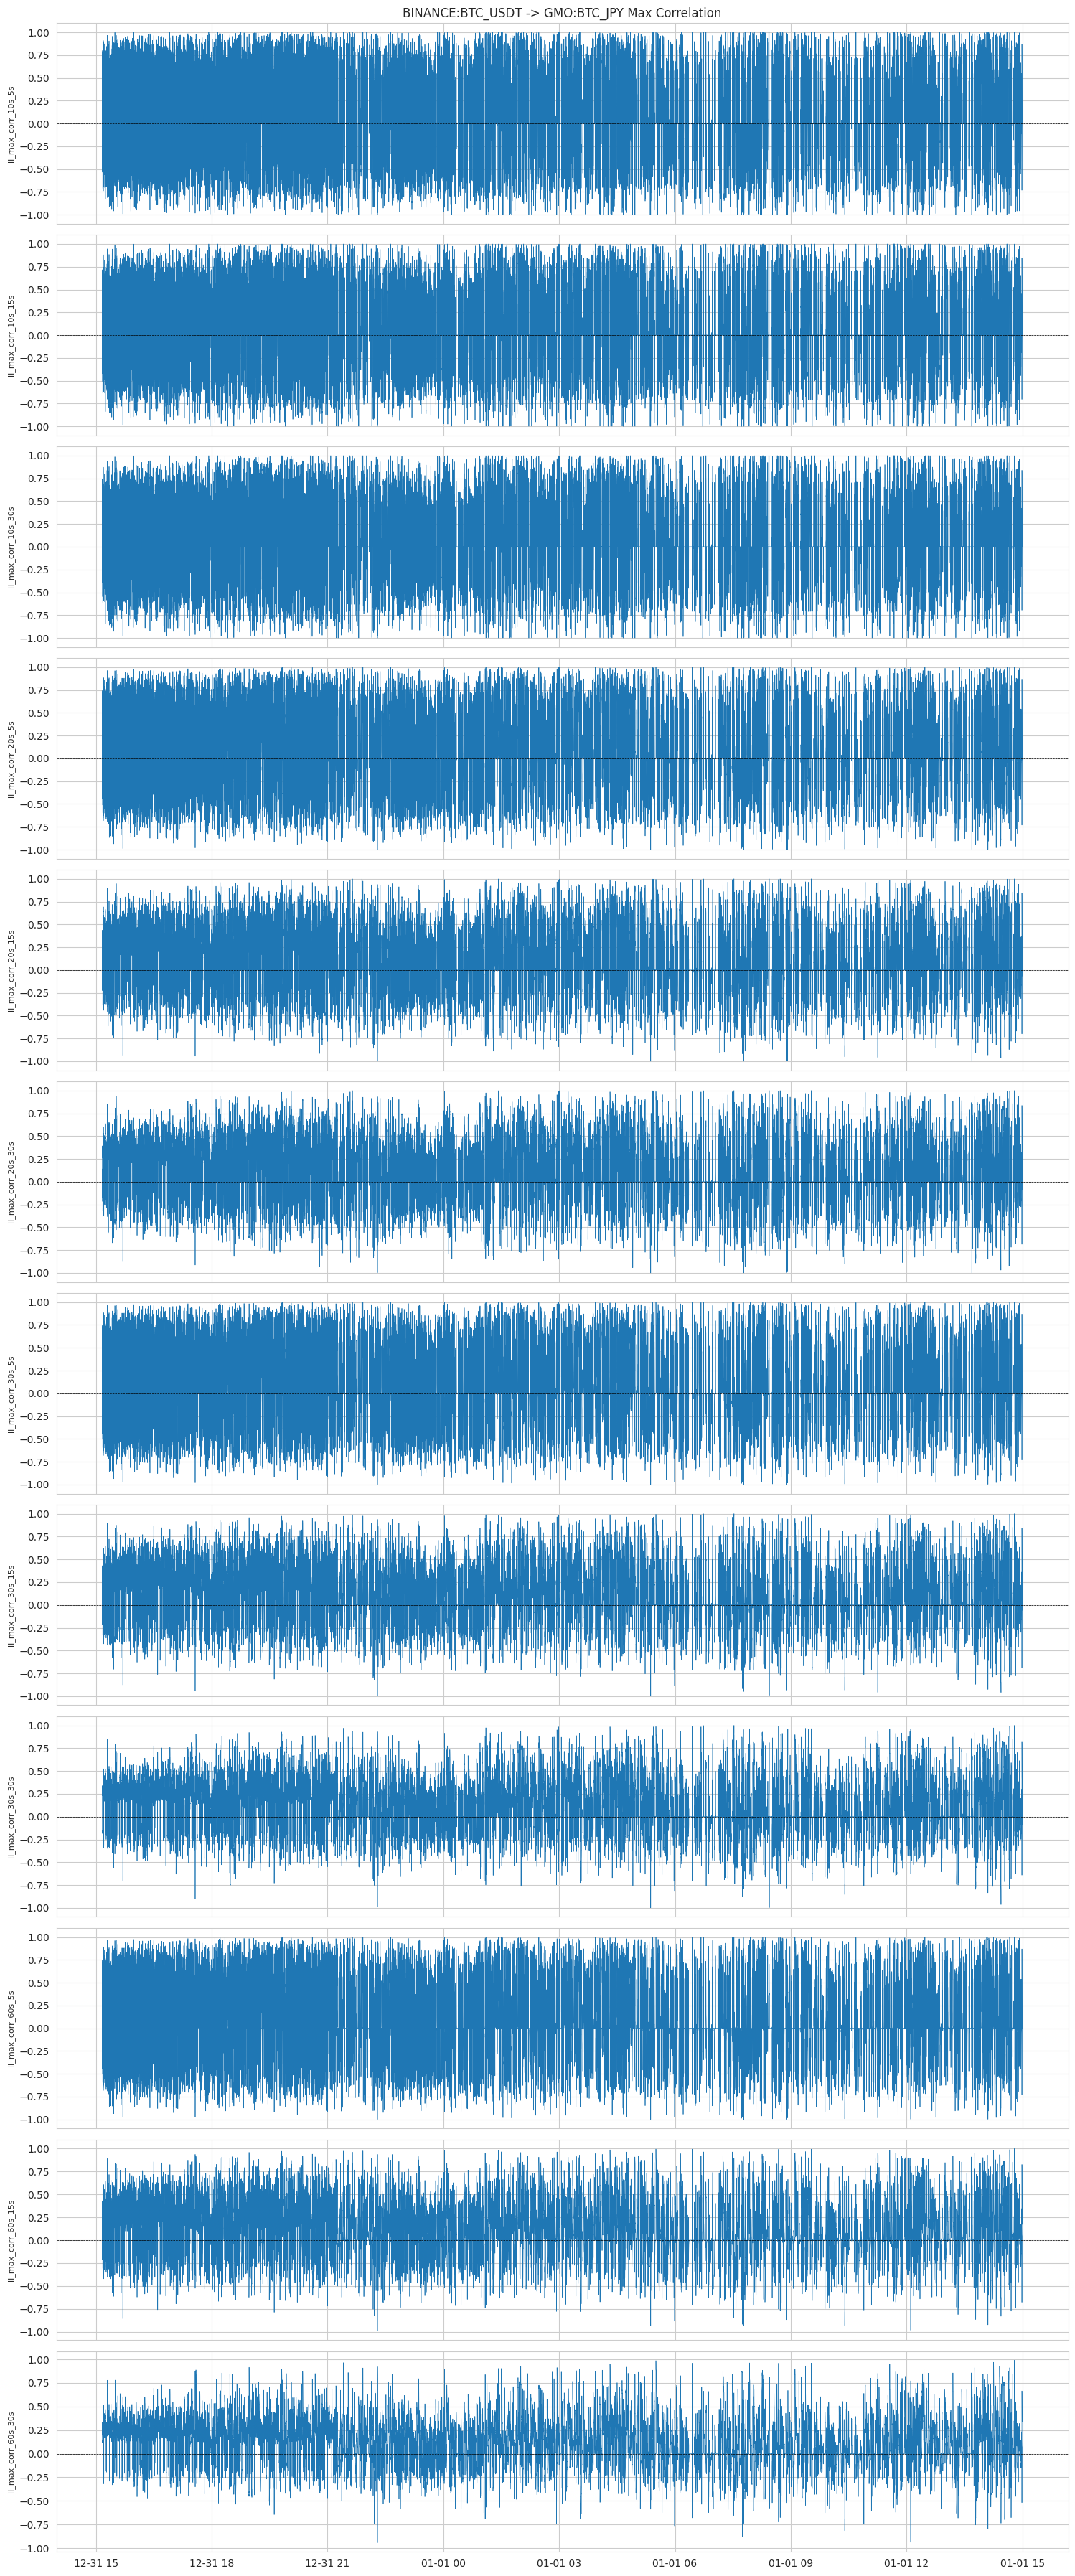

In [5]:
# Plot ll_max_corr
if corr_cols:
    fig, axes = plt.subplots(len(corr_cols), 1, figsize=(15, 3 * len(corr_cols)), sharex=True)
    if len(corr_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, corr_cols):
        ax.plot(df['datetime'], df[col], linewidth=0.5)
        ax.set_ylabel(col, fontsize=8)
        ax.axhline(y=0, color='black', linewidth=0.5, linestyle='--')
    axes[0].set_title(f'{MARKET_LEAD.id} -> {MARKET_LAG.id} Max Correlation')
    plt.tight_layout()
    plt.show()

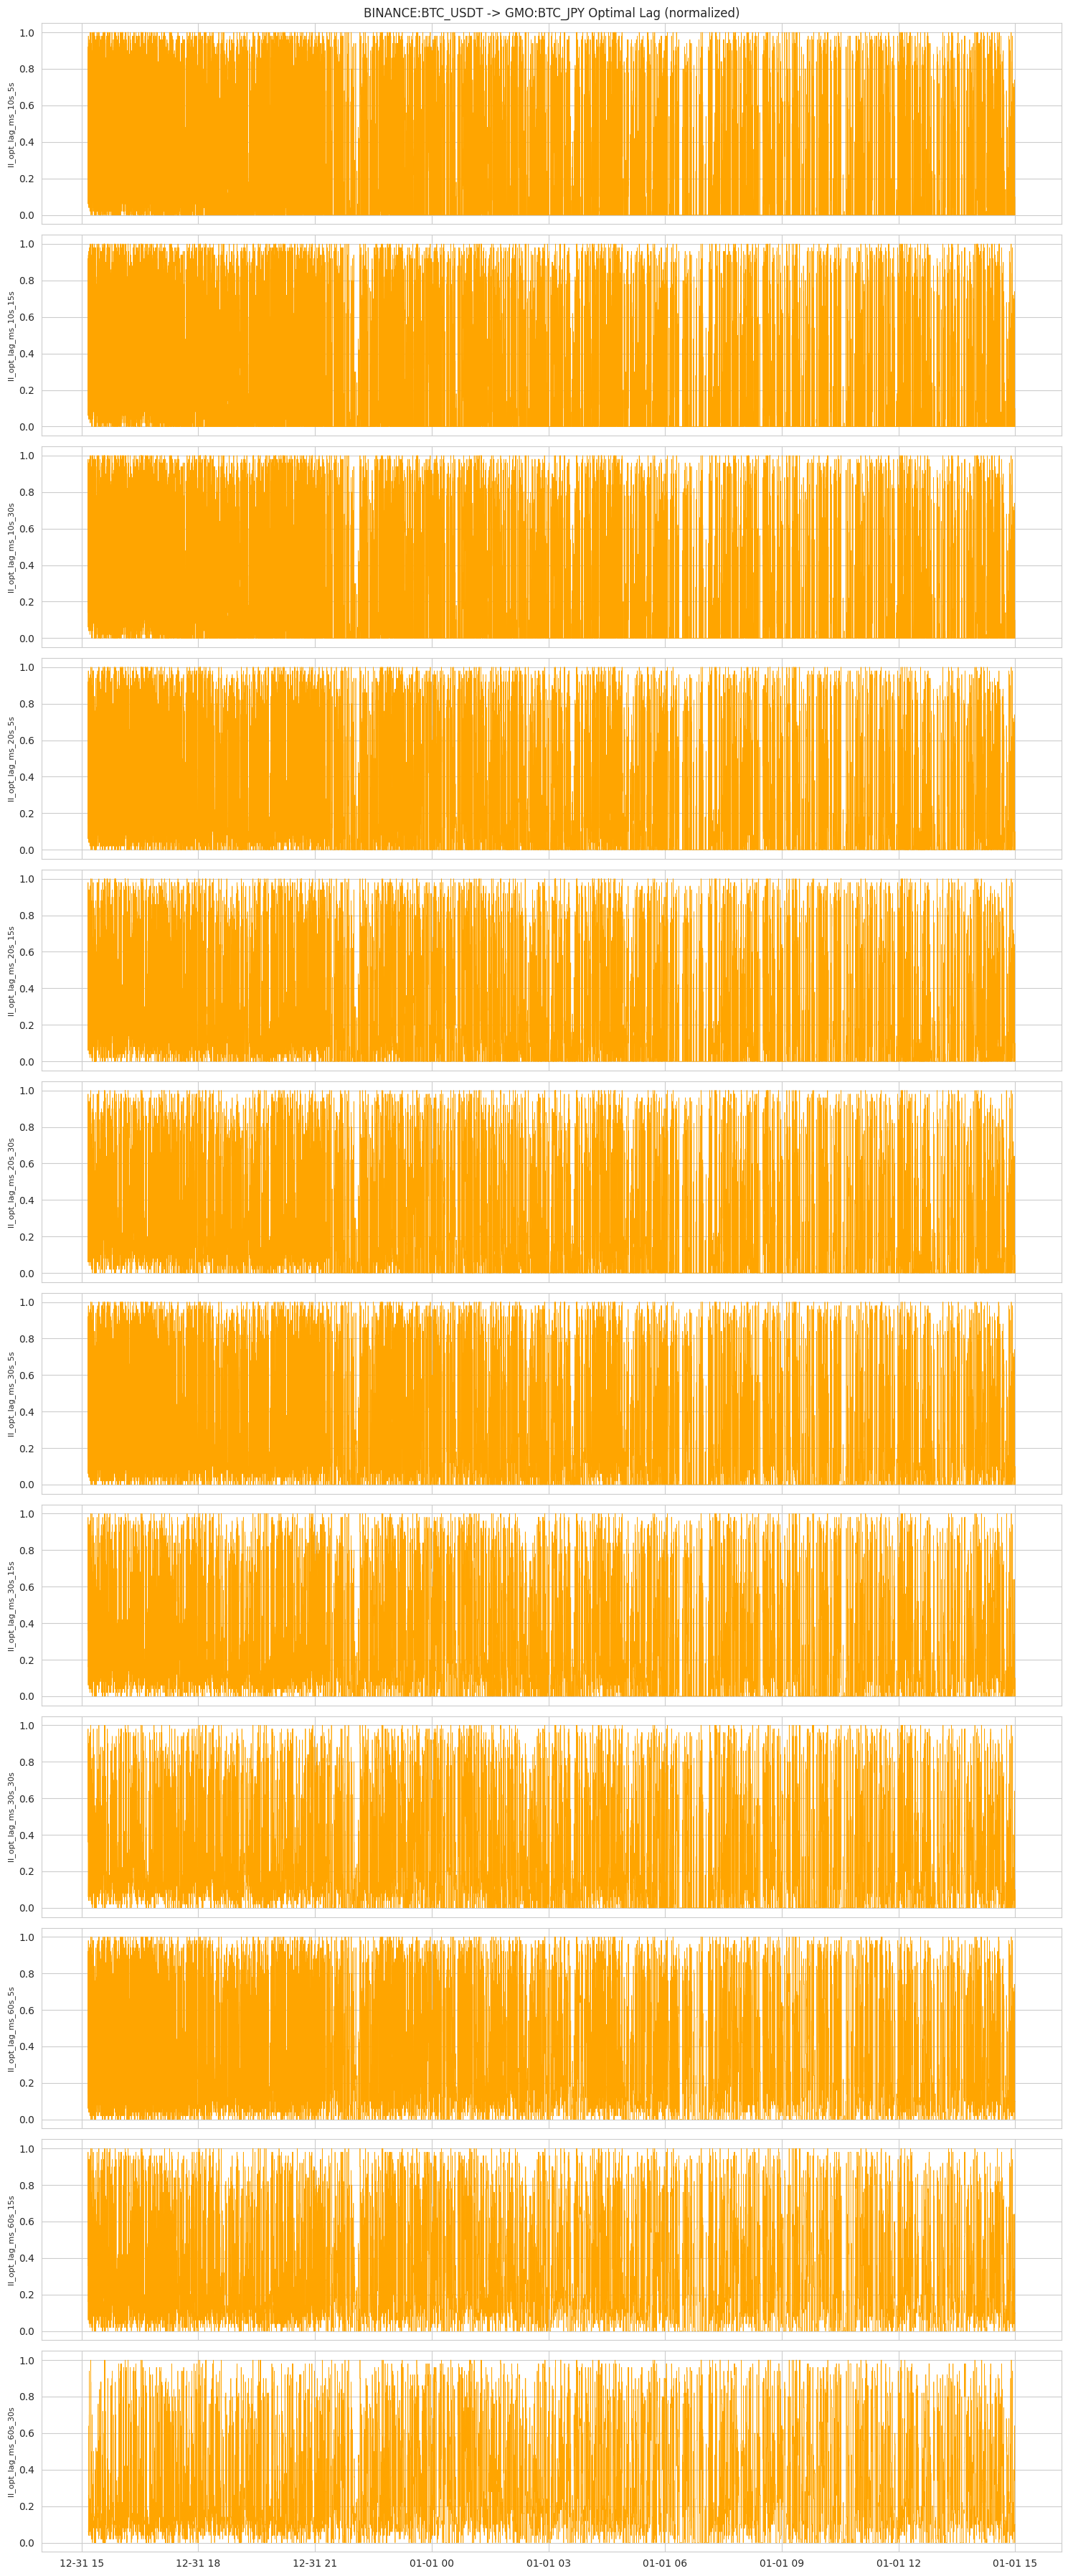

In [6]:
# Plot ll_opt_lag_ms (normalized)
if lag_cols:
    fig, axes = plt.subplots(len(lag_cols), 1, figsize=(15, 3 * len(lag_cols)), sharex=True)
    if len(lag_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, lag_cols):
        ax.plot(df['datetime'], df[col], linewidth=0.5, color='orange')
        ax.set_ylabel(col, fontsize=8)
    axes[0].set_title(f'{MARKET_LEAD.id} -> {MARKET_LAG.id} Optimal Lag (normalized)')
    plt.tight_layout()
    plt.show()

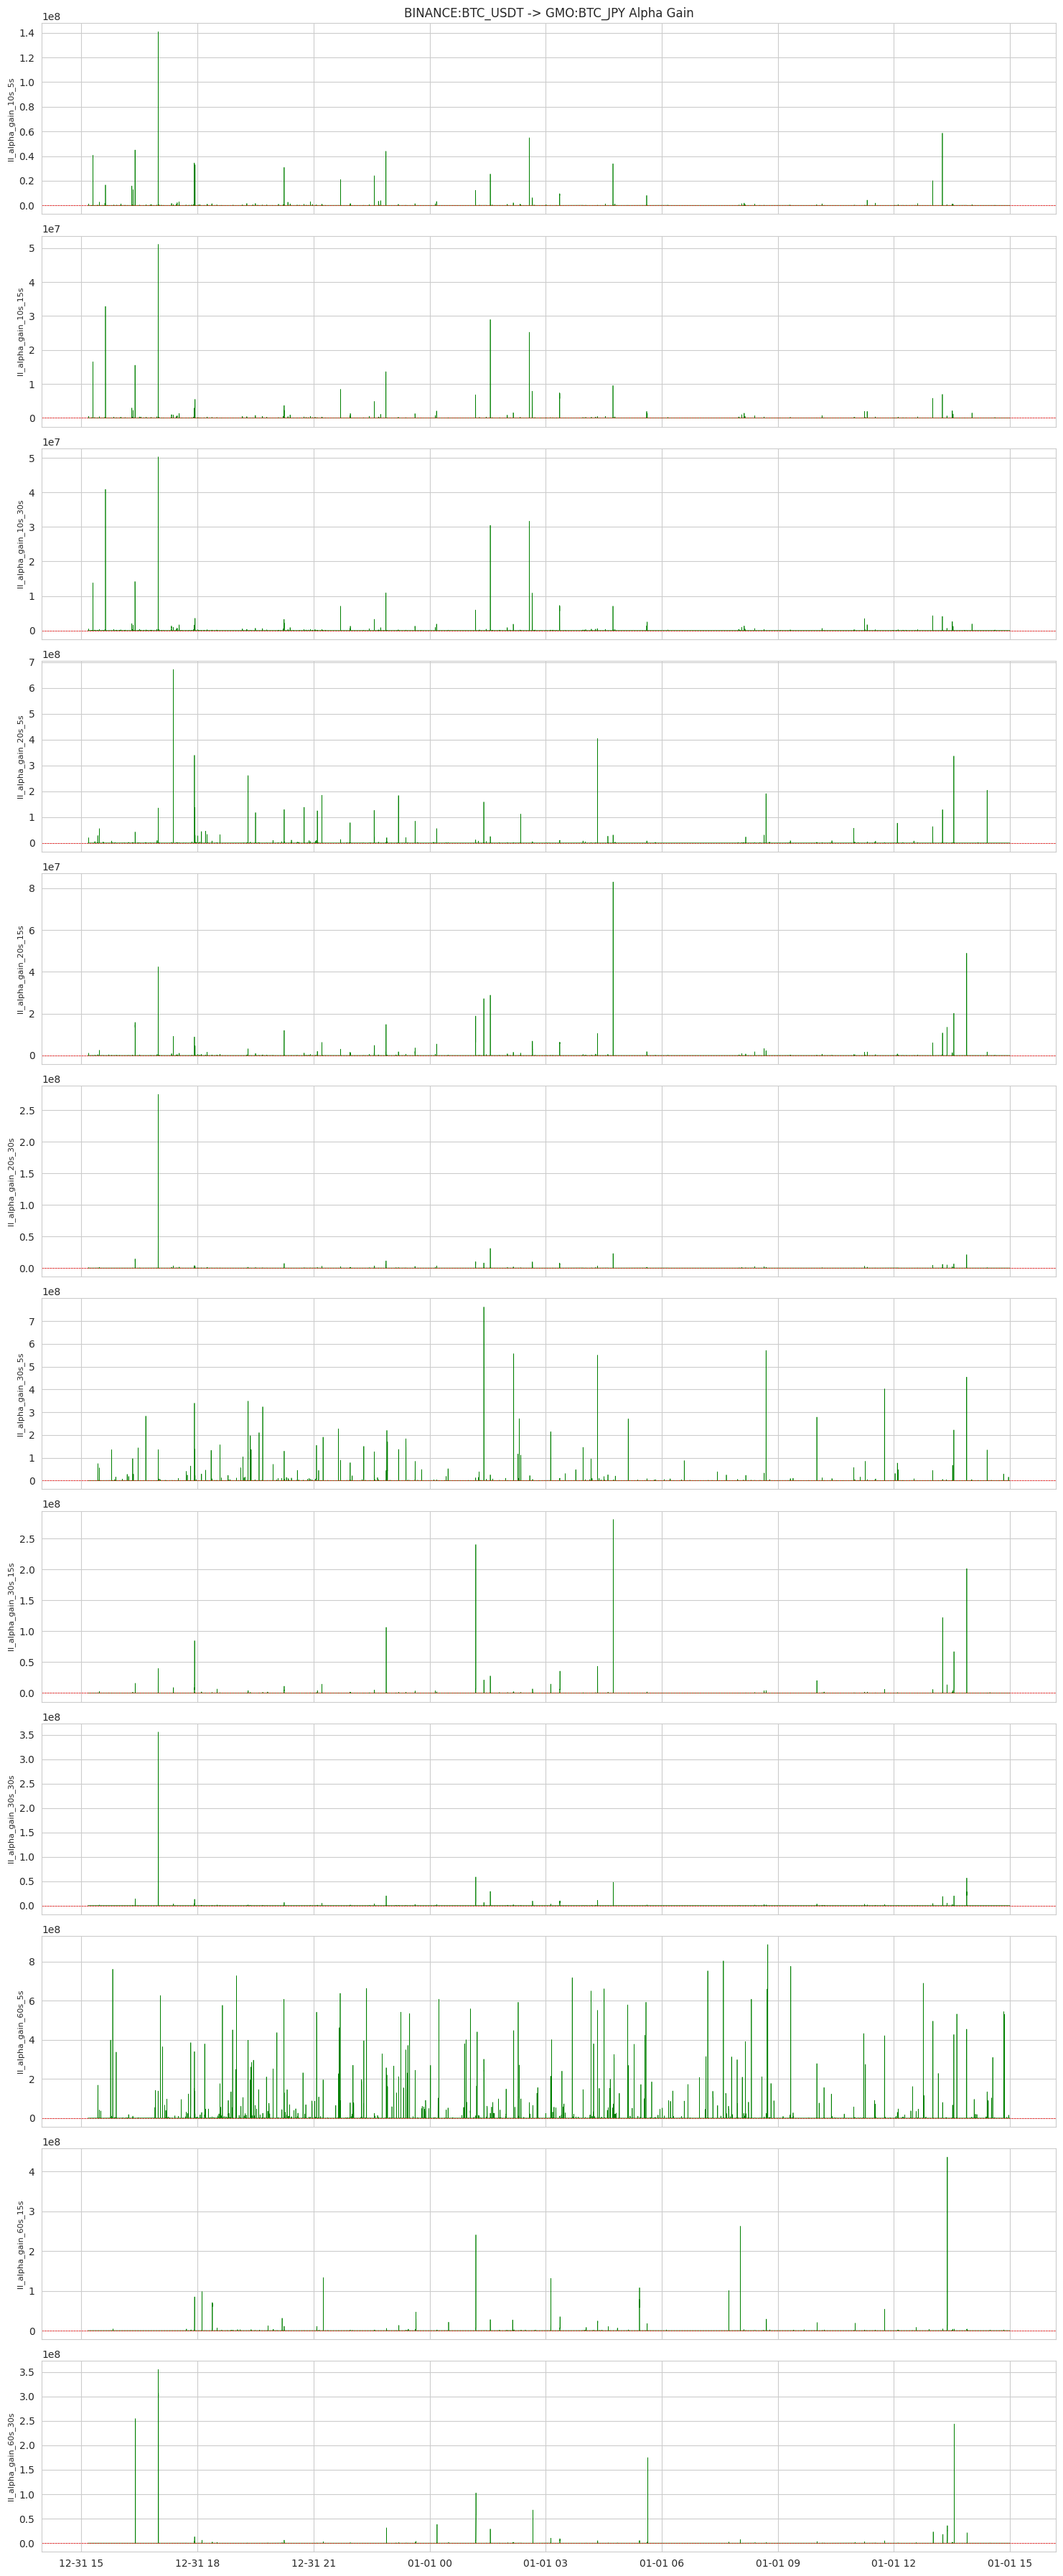

In [7]:
# Plot ll_alpha_gain
if gain_cols:
    fig, axes = plt.subplots(len(gain_cols), 1, figsize=(15, 3 * len(gain_cols)), sharex=True)
    if len(gain_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, gain_cols):
        ax.plot(df['datetime'], df[col], linewidth=0.5, color='green')
        ax.set_ylabel(col, fontsize=8)
        ax.axhline(y=1, color='red', linewidth=0.5, linestyle='--')
    axes[0].set_title(f'{MARKET_LEAD.id} -> {MARKET_LAG.id} Alpha Gain')
    plt.tight_layout()
    plt.show()

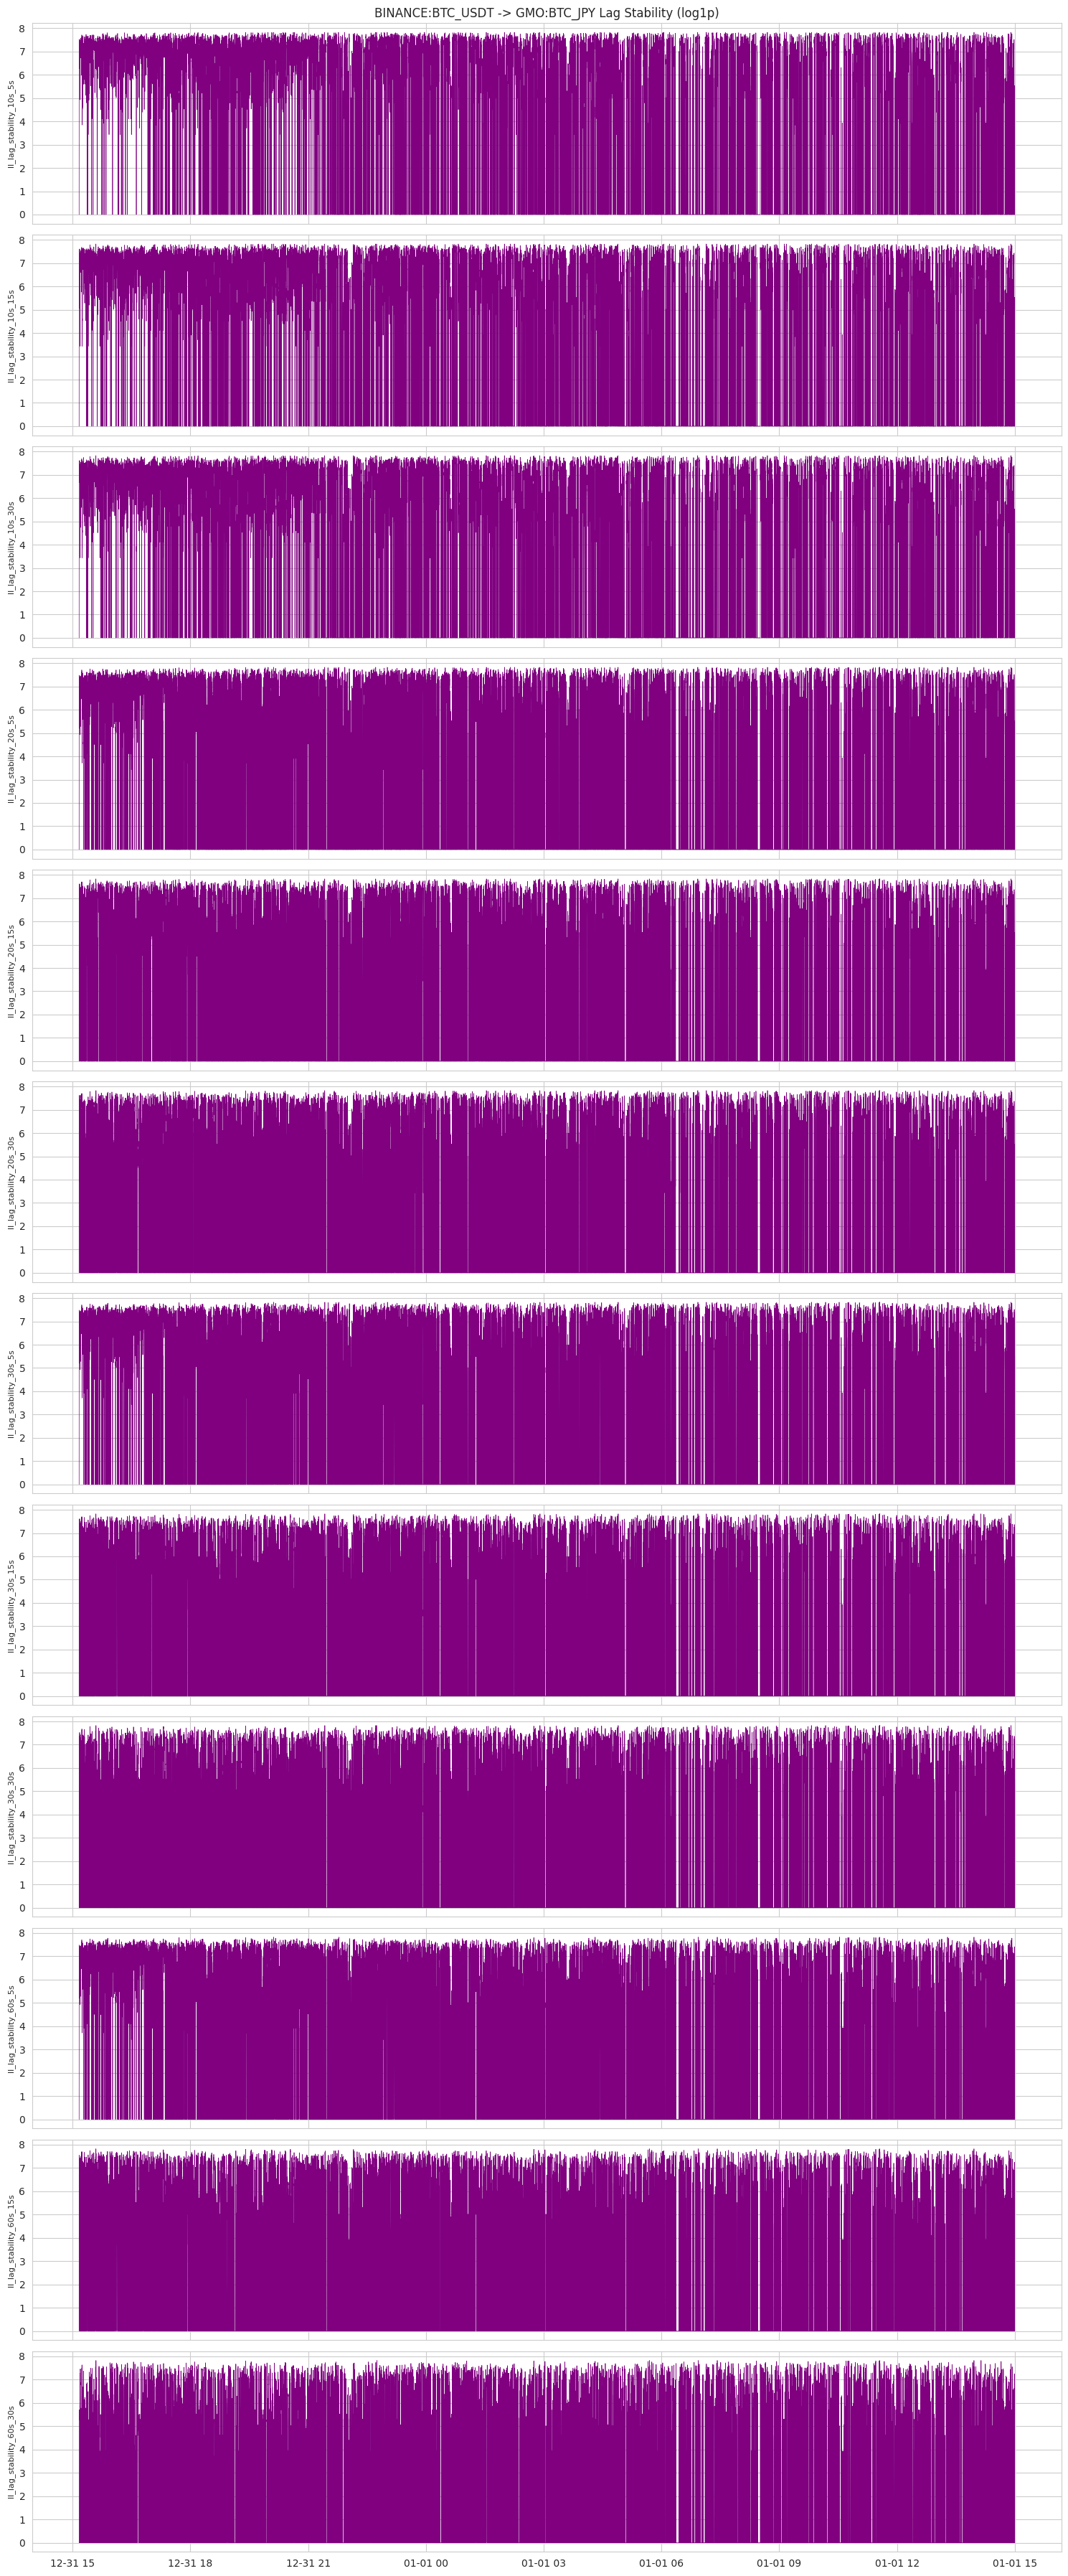

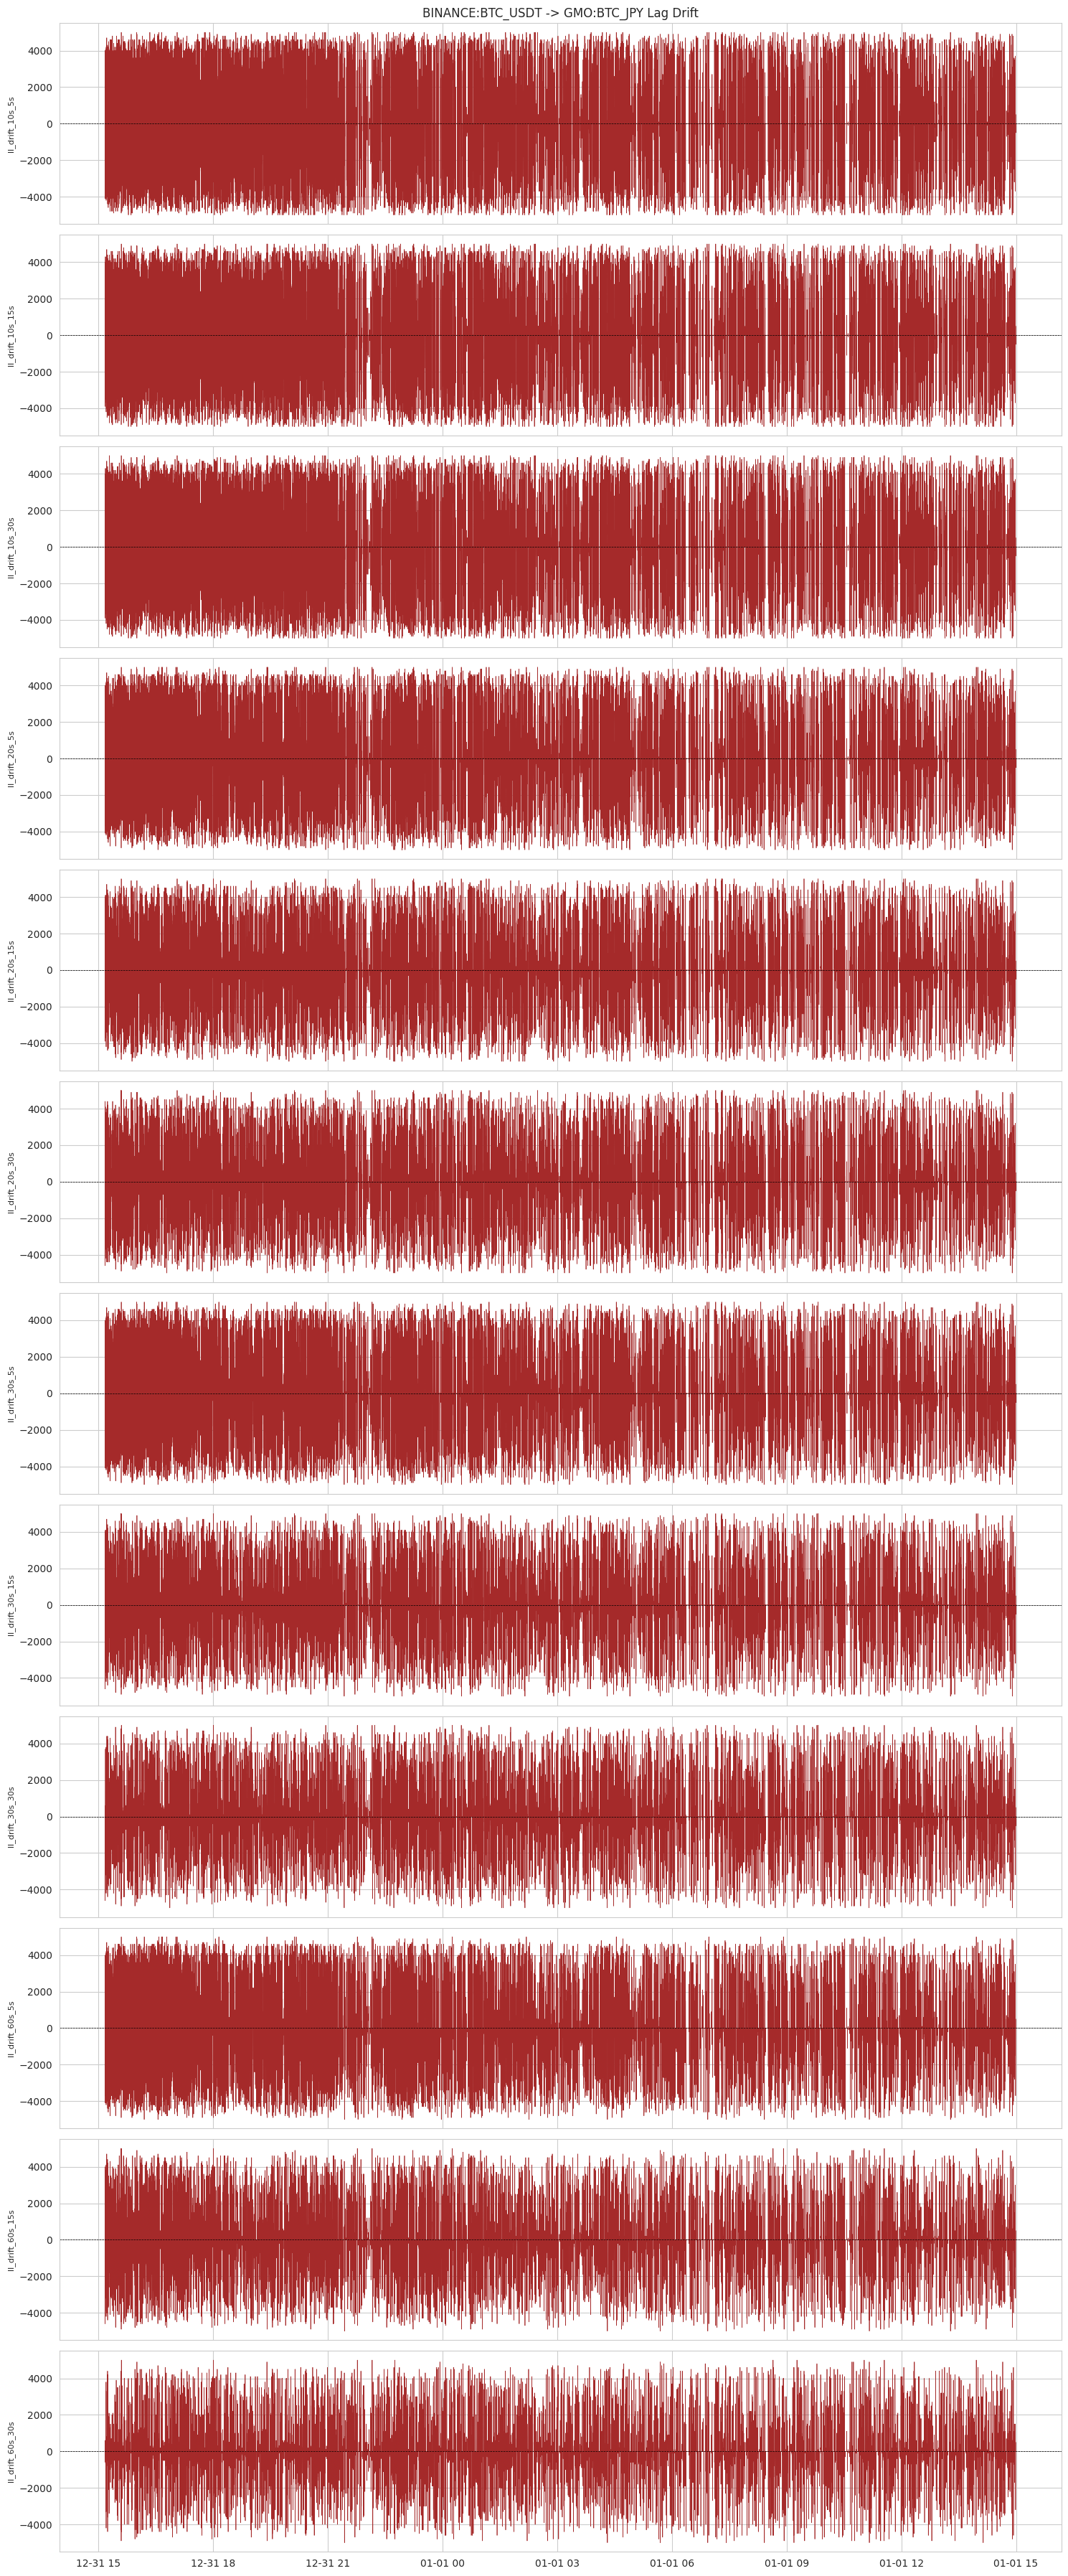

In [8]:
# Plot ll_lag_stability and ll_drift
if stability_cols:
    fig, axes = plt.subplots(len(stability_cols), 1, figsize=(15, 3 * len(stability_cols)), sharex=True)
    if len(stability_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, stability_cols):
        ax.plot(df['datetime'], df[col], linewidth=0.5, color='purple')
        ax.set_ylabel(col, fontsize=8)
    axes[0].set_title(f'{MARKET_LEAD.id} -> {MARKET_LAG.id} Lag Stability (log1p)')
    plt.tight_layout()
    plt.show()

if drift_cols:
    fig, axes = plt.subplots(len(drift_cols), 1, figsize=(15, 3 * len(drift_cols)), sharex=True)
    if len(drift_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, drift_cols):
        ax.plot(df['datetime'], df[col], linewidth=0.5, color='brown')
        ax.set_ylabel(col, fontsize=8)
        ax.axhline(y=0, color='black', linewidth=0.5, linestyle='--')
    axes[0].set_title(f'{MARKET_LEAD.id} -> {MARKET_LAG.id} Lag Drift')
    plt.tight_layout()
    plt.show()

## 4. Correlation Heatmap

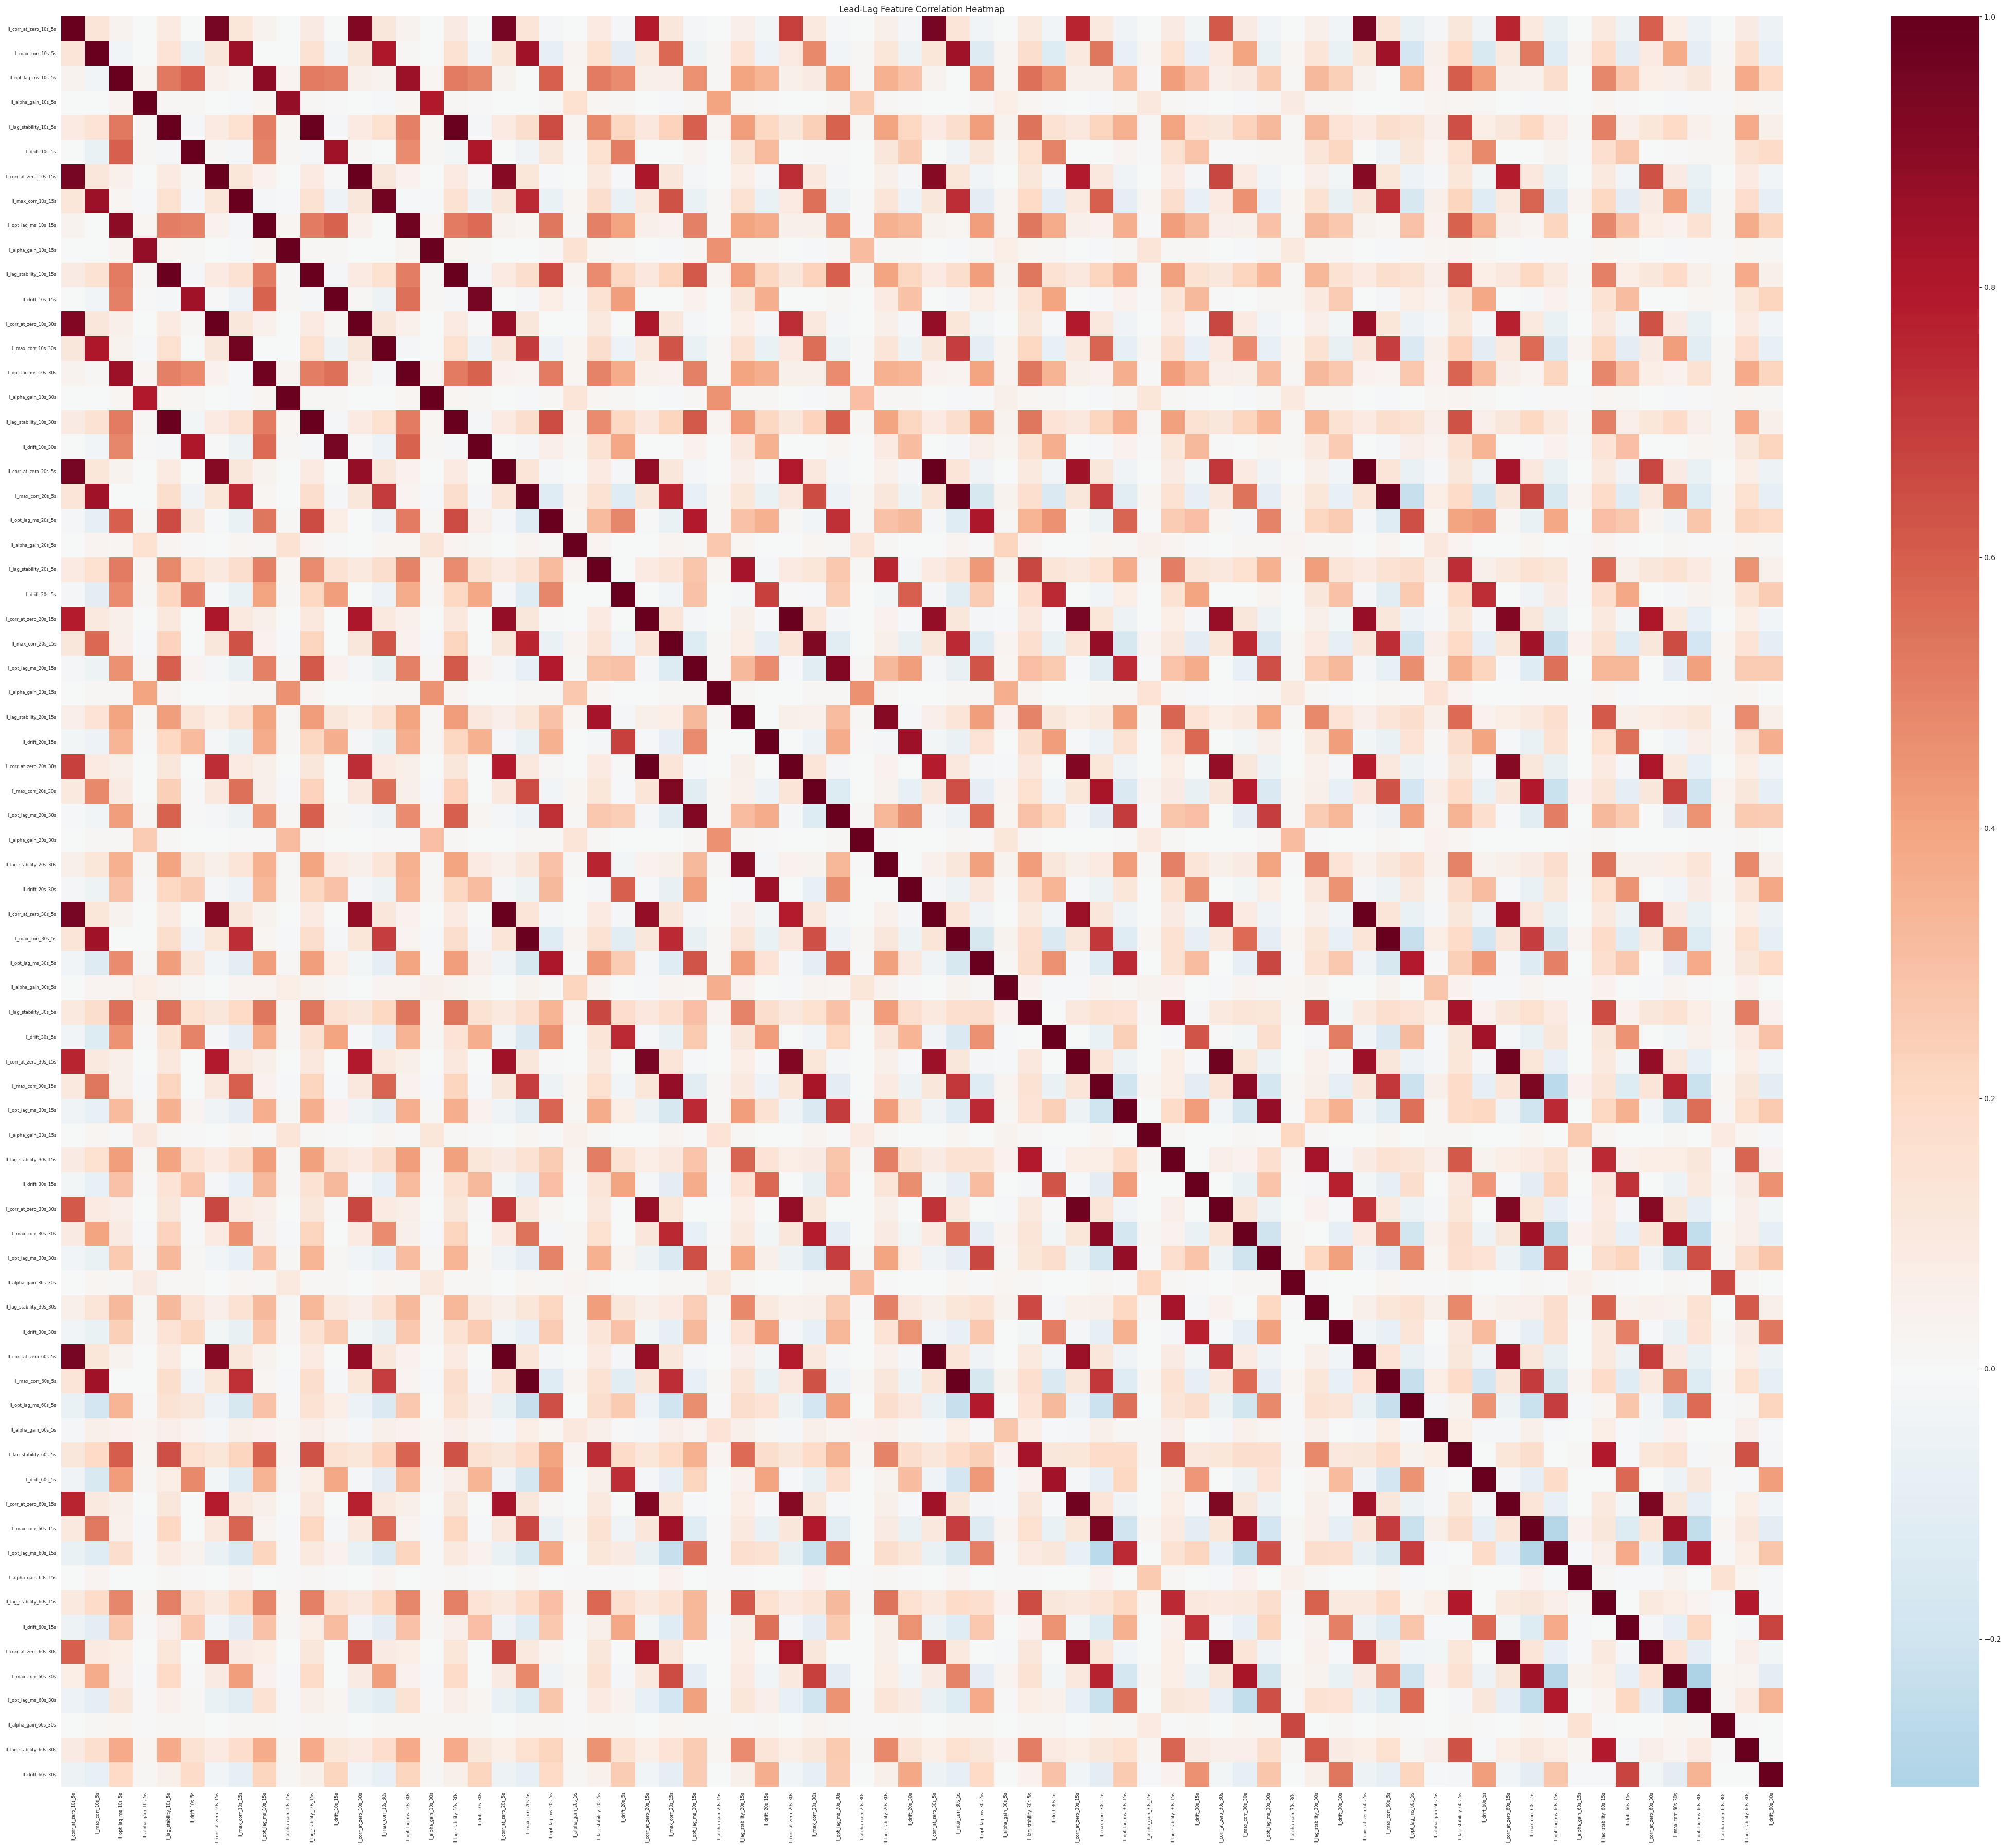

In [9]:
# Correlation heatmap across all lead-lag features
ll_cols = [c for c in df.columns if c.startswith('ll_')]
if ll_cols:
    fig, ax = plt.subplots(figsize=(max(10, len(ll_cols) * 0.6), max(8, len(ll_cols) * 0.5)))
    corr_matrix = df[ll_cols].corr()
    sns.heatmap(corr_matrix, annot=False, cmap='RdBu_r', center=0, ax=ax,
                xticklabels=True, yticklabels=True)
    ax.set_title('Lead-Lag Feature Correlation Heatmap')
    plt.xticks(fontsize=6, rotation=90)
    plt.yticks(fontsize=6)
    plt.tight_layout()
    plt.show()

## 5. Data Consistency Summary

In [10]:
print('=' * 60)
print('Data Consistency Summary')
print('=' * 60)

print(f'\n--- LeadLag Features ---')
print(f'  Leader:     {MARKET_LEAD.id}')
print(f'  Target:     {MARKET_LAG.id}')
print(f'  Rows:       {len(df):,}')
print(f'  Columns:    {len(df.columns)}')
ts_min = pd.to_datetime(df['ts'].min(), unit='s') if not df.empty else 'N/A'
ts_max = pd.to_datetime(df['ts'].max(), unit='s') if not df.empty else 'N/A'
print(f'  Time range: {ts_min} ~ {ts_max}')
total_nan = df.isna().sum().sum()
print(f'  Total NaN:  {total_nan:,} ({total_nan / max(df.size, 1) * 100:.2f}%)')
dupes = df.duplicated(subset=['ts']).sum()
print(f'  Duplicate timestamps: {dupes}')

# Sanity checks on correlation values
print(f'\n--- Sanity Checks ---')
for col in corr_cols:
    vals = df[col].dropna()
    in_range = ((vals >= -1) & (vals <= 1)).all()
    print(f'  {col} in [-1, 1]: {in_range}')

for col in lag_cols:
    vals = df[col].dropna()
    in_range = ((vals >= 0) & (vals <= 1)).all()
    print(f'  {col} in [0, 1]: {in_range}')

Data Consistency Summary

--- LeadLag Features ---
  Leader:     BINANCE:BTC_USDT
  Target:     GMO:BTC_JPY
  Rows:       85,800
  Columns:    74
  Time range: 2025-12-31 15:10:00.299999952 ~ 2026-01-01 14:59:59.299999952
  Total NaN:  0 (0.00%)
  Duplicate timestamps: 0

--- Sanity Checks ---
  ll_max_corr_10s_5s in [-1, 1]: True
  ll_max_corr_10s_15s in [-1, 1]: True
  ll_max_corr_10s_30s in [-1, 1]: True
  ll_max_corr_20s_5s in [-1, 1]: True
  ll_max_corr_20s_15s in [-1, 1]: True
  ll_max_corr_20s_30s in [-1, 1]: True
  ll_max_corr_30s_5s in [-1, 1]: True
  ll_max_corr_30s_15s in [-1, 1]: True
  ll_max_corr_30s_30s in [-1, 1]: True
  ll_max_corr_60s_5s in [-1, 1]: True
  ll_max_corr_60s_15s in [-1, 1]: True
  ll_max_corr_60s_30s in [-1, 1]: True
  ll_opt_lag_ms_10s_5s in [0, 1]: True
  ll_opt_lag_ms_10s_15s in [0, 1]: True
  ll_opt_lag_ms_10s_30s in [0, 1]: True
  ll_opt_lag_ms_20s_5s in [0, 1]: True
  ll_opt_lag_ms_20s_15s in [0, 1]: True
  ll_opt_lag_ms_20s_30s in [0, 1]: True
  l